# Right-Party Contact Prediction & Skip-Trace Prioritisation
**Problem Statement 2 – CreditNirvana**

**Goal:** for every phone number on file, estimate how likely the next call is to reach the borrower (a *right-party contact*, RPC), work out what *state* the number is in (working, avoiding us, dead, recycled to a stranger...), and decide when paying for a **skip-trace** is worth it.

**Approach (kept deliberately simple):**
1. **Ageing HMM** – a Hidden Markov Model that tracks the hidden state of each phone number. Between calls the belief is aged with a matrix exponential, so old evidence counts for less.
2. **Gradient-boosting model** (scikit-learn) – predicts P(RPC) for the next call from call history + HMM beliefs, then calibrated with isotonic regression.
3. **Skip-trace value of information (VOI)** – a logistic regression predicts whether a trace will find a new contact; VOI weighs that against the trace cost.

**Leakage rules we follow:** every feature for a call uses only *earlier* calls; accounts are split into train / validation / test using the provided `splits.csv`; the test split is only used for the final scores.

**To run:** put the CSV files next to this notebook (or change `DATA_DIR` below) and run all cells top to bottom.

## 1. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import expm
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

DATA_DIR = Path(".")                      # folder that contains the CSV files
OUT_DIR = Path("outputs")                 # results are written here
OUT_DIR.mkdir(exist_ok=True)

ASOF = pd.Timestamp("2026-06-30")         # "today" for production scoring (end of the dial log)

# Skip-trace economics (assumptions, explained in section 8)
H_CALLS = 10          # we plan to make about 10 more calls
RHO = 0.049           # extra share of the overdue amount paid within 14 days of a right-party contact
N_WINDOWS = 2         # a found contact stays useful for ~2 such windows
SWITCH_THRESHOLD = 0.10      # best phone below this P(RPC) per call -> do not keep redialling it
RECYCLED_THRESHOLD = 0.50    # P(recycled) above this -> put the number on the do-not-call list

## 2. Load and clean the data
* A phone number can be shared by several accounts, so the key is **(account_id, phone_id)**.
* **RPC label:** the line was answered, there was real talk time, and the disposition is an `rpc_*` outcome (24 rows are logged as RPC without an answered call – those are marked as noisy and left out of training).
* Each call is turned into one **symbol** the HMM can read (RPC, no answer, rejected, ...).

In [2]:
def read(name, **kwargs):
    return pd.read_csv(DATA_DIR / f"{name}.csv", **kwargs)

dials    = read("dial_attempts", parse_dates=["attempt_ts"])
phones   = read("phones", parse_dates=["added_date"]).drop_duplicates(["account_id", "phone_id"])
accounts = read("accounts")
splits   = read("splits")
verified = read("verified_contact_points")
traces   = read("skip_traces", parse_dates=["trace_date"])

# --- label ---
looks_like_rpc = dials.disposition.str.startswith("rpc_") | (dials.disposition == "language_barrier")
answered = (dials.network_response == "answered") & (dials.talk_duration_s > 0)
dials["is_rpc"] = (looks_like_rpc & answered).astype(int)
dials["label_noisy"] = (looks_like_rpc & ~answered).astype(int)

# --- HMM symbols (one per call) ---
DISPOSITION_TO_SYMBOL = {
    "no_answer": "NO_ANSWER", "call_rejected": "REJECTED", "not_reachable": "NOT_REACHABLE",
    "switched_off": "SWITCHED_OFF", "invalid_number": "INVALID",
    "third_party_contact": "THIRD_PARTY", "third_party_ptp": "THIRD_PARTY", "wrong_number": "WRONG_NUMBER",
}
dials["symbol"] = dials.disposition.map(DISPOSITION_TO_SYMBOL).fillna("NO_ANSWER")
dials.loc[dials.is_rpc == 1, "symbol"] = "RPC"

# --- simple 0/1 flags used for the history features ---
dials["dead_net"]     = dials.symbol.isin(["NOT_REACHABLE", "SWITCHED_OFF", "INVALID"]).astype(int)
dials["rejected"]     = (dials.symbol == "REJECTED").astype(int)
dials["wrong_number"] = (dials.symbol == "WRONG_NUMBER").astype(int)
dials["real"] = 1                          # 1 = a call that really happened (0 = a "what if" query row, see section 6)

print(f"{len(dials):,} calls | RPC rate {dials.is_rpc.mean():.1%} | noisy labels {dials.label_noisy.sum()}")
dials.symbol.value_counts()

51,105 calls | RPC rate 16.5% | noisy labels 24


## 3. The Ageing HMM
**States** (hidden – we never see them directly): `REACH` (working, borrower answers), `AVOID` (working, borrower screens us), `TEMP` (temporarily unreachable), `DEAD` (switched off / invalid), `RECYC` (recycled to a stranger), `THIRD` (relative / employer / reference).

* **Emission matrix `B`** – how likely each call outcome is in each state (e.g. a `DEAD` number mostly shows *switched off*; an `AVOID` number shows many *rejected* calls but almost no RPCs). Values are domain-informed, based on the patterns in the data.
* **Rate matrix `Q`** – how fast a number drifts from one state to another **per day** (e.g. `DEAD` slowly turns into `RECYC`; `TEMP` recovers quickly).
* **Ageing:** after a gap of `d` days the belief is multiplied by `expm(Q * d)`, so uncertainty grows when evidence is old.
* **Starting belief** depends on who the number belongs to (the borrower vs a reference/employer).

In [3]:
STATES  = ["REACH", "AVOID", "TEMP", "DEAD", "RECYC", "THIRD"]
SYMBOLS = ["RPC", "NO_ANSWER", "REJECTED", "NOT_REACHABLE", "SWITCHED_OFF", "INVALID", "THIRD_PARTY", "WRONG_NUMBER"]
SYMBOL_ID = {s: i for i, s in enumerate(SYMBOLS)}

#                      RPC   NO_ANS  REJ   NOT_REACH  SW_OFF  INVALID  THIRD  WRONG
EMISSION = np.array([[0.24,  0.52,  0.14,  0.05,  0.01,  0.00,  0.02,  0.02],   # REACH
                     [0.03,  0.50,  0.40,  0.03,  0.01,  0.00,  0.02,  0.01],   # AVOID
                     [0.08,  0.25,  0.08,  0.45,  0.12,  0.00,  0.01,  0.01],   # TEMP
                     [0.01,  0.15,  0.05,  0.22,  0.52,  0.03,  0.01,  0.01],   # DEAD
                     [0.03,  0.28,  0.05,  0.12,  0.22,  0.00,  0.05,  0.25],   # RECYC
                     [0.08,  0.40,  0.07,  0.05,  0.01,  0.00,  0.33,  0.06]])  # THIRD

# Rate of moving between states, per day. Each row sums to 0 (it is a "generator" matrix).
RATES = np.array([[-0.011, 0.004, 0.004, 0.003, 0.000, 0.000],    # REACH  -> slowly drifts
                  [ 0.004,-0.009, 0.002, 0.003, 0.000, 0.000],    # AVOID
                  [ 0.060, 0.000,-0.070, 0.010, 0.000, 0.000],    # TEMP   -> usually recovers fast
                  [ 0.000, 0.000, 0.000,-0.006, 0.006, 0.000],    # DEAD   -> may be recycled to a stranger
                  [ 0.000, 0.000, 0.000, 0.002,-0.002, 0.000],    # RECYC
                  [ 0.000, 0.000, 0.000, 0.000, 0.000, 0.000]])   # THIRD  -> stays third party

#                     REACH AVOID TEMP  DEAD  RECYC THIRD
PRIOR_BORROWER = np.array([0.60, 0.10, 0.05, 0.10, 0.10, 0.05])
PRIOR_OTHER    = np.array([0.10, 0.02, 0.02, 0.06, 0.05, 0.75])


class AgeingHMM:
    """Tracks the hidden state of one phone number across calls that are spread unevenly in time."""

    def __init__(self, emission, rates):
        emission = emission + 1e-3                                   # avoid impossible (zero) outcomes
        self.B = emission / emission.sum(axis=1, keepdims=True)
        self.Q = rates
        self._cache = {}

    def transition(self, days):
        """Probability of moving between states over `days` days = expm(Q * days)."""
        days = int(min(max(days, 0), 365))
        if days not in self._cache:
            self._cache[days] = expm(self.Q * days)
        return self._cache[days]

    def beliefs_before_each_call(self, symbol_ids, gap_days, is_real, prior):
        """For every row return the belief held JUST BEFORE that row (so it never sees its own outcome).
        Rows with is_real == 0 are 'what if' queries: they age the belief but add no evidence."""
        belief, out = prior.copy(), np.empty((len(symbol_ids), len(prior)))
        for t in range(len(symbol_ids)):
            if t > 0:
                belief = belief @ self.transition(gap_days[t])       # age the belief
            out[t] = belief
            if is_real[t]:                                           # then learn from what happened
                belief = belief * self.B[:, symbol_ids[t]]
                belief /= belief.sum()
        return out


hmm = AgeingHMM(EMISSION, RATES)
print("Rate matrix rows sum to zero:", np.allclose(RATES.sum(axis=1), 0))
print("Aged transition matrix is a valid probability matrix:", np.allclose(hmm.transition(30).sum(axis=1), 1))

Rate matrix rows sum to zero: True
Aged transition matrix is a valid probability matrix: True


## 4. Features (history + HMM beliefs)
`add_hmm_beliefs` runs the HMM over every phone's call sequence. `build_features` then adds simple history features. **Everything is computed from earlier calls only** (`cumsum` minus the current row, `shift`).

In [4]:
PAIR = ["account_id", "phone_id"]


def attach_metadata(df):
    """Add phone- and account-level columns."""
    df = df.merge(phones[PAIR + ["relation_recorded", "source", "priority_slot"]], on=PAIR, how="left")
    acc = accounts[["account_id", "portfolio", "bucket_start", "overdue_start"]].copy()
    acc["log_overdue"] = np.log1p(acc.overdue_start)
    df = df.merge(acc[["account_id", "portfolio", "bucket_start", "log_overdue"]], on="account_id", how="left")
    df["split"] = df.account_id.map(splits.set_index("account_id").split)
    return df


def add_hmm_beliefs(df):
    """Run the ageing HMM over each (account, phone) sequence -> columns P_REACH ... P_THIRD."""
    df = df.sort_values(PAIR + ["attempt_ts"]).reset_index(drop=True)
    gaps = df.groupby(PAIR).attempt_ts.diff().dt.days.fillna(0).to_numpy()
    symbol_ids = df.symbol.map(SYMBOL_ID).to_numpy()
    is_real = df.real.to_numpy().astype(bool)
    belongs_to_borrower = (df.relation_recorded == "self").to_numpy()

    beliefs = np.zeros((len(df), len(STATES)))
    for _, rows in df.groupby(PAIR).indices.items():
        prior = PRIOR_BORROWER if belongs_to_borrower[rows[0]] else PRIOR_OTHER
        beliefs[rows] = hmm.beliefs_before_each_call(symbol_ids[rows], gaps[rows], is_real[rows], prior)
    df[[f"P_{s}" for s in STATES]] = beliefs
    df["P_valid"] = df.P_REACH + df.P_AVOID + df.P_TEMP          # number still belongs to the borrower
    return df


def build_features(df):
    """History features. Only rows with real == 1 count as evidence; every value looks strictly backwards."""
    g = [df.account_id, df.phone_id]

    def earlier_count(flag):                                     # how many earlier real calls had this flag
        flag = flag * df.real
        return flag.groupby(g).cumsum() - flag

    df["prev_attempts"] = earlier_count(pd.Series(1, index=df.index))
    df["prev_rpc"]      = earlier_count(df.is_rpc)
    df["prev_dead"]     = earlier_count(df.dead_net)
    df["prev_reject"]   = earlier_count(df.rejected)
    df["prev_wrong"]    = earlier_count(df.wrong_number)
    n = df.prev_attempts.replace(0, np.nan)
    df["rpc_rate"], df["dead_rate"], df["reject_rate"] = df.prev_rpc / n, df.prev_dead / n, df.prev_reject / n

    # consecutive failed calls since the last RPC
    failed = ((df.real == 1) & (df.is_rpc == 0)).astype(int)
    failed_total = failed.groupby(g).cumsum()
    marker = failed_total.where((df.real == 1) & (df.is_rpc == 1))
    last_marker = marker.groupby(g).transform(lambda s: s.shift(1).ffill()).fillna(0)
    df["fail_streak"] = failed_total - failed - last_marker

    # days since the last real call / last RPC on this number
    last_call = df.attempt_ts.where(df.real == 1).groupby(g).transform(lambda s: s.shift(1).ffill())
    last_rpc  = df.attempt_ts.where((df.real == 1) & (df.is_rpc == 1)).groupby(g).transform(lambda s: s.shift(1).ffill())
    df["days_since_call"] = (df.attempt_ts - last_call).dt.days
    df["days_since_rpc"]  = (df.attempt_ts - last_rpc).dt.days

    # does the borrower answer on ANOTHER phone? (a strong sign of avoiding this one)
    by_time = df.sort_values("attempt_ts")
    rpc_real = by_time.is_rpc * by_time.real
    acct_earlier = rpc_real.groupby(by_time.account_id).cumsum() - rpc_real
    df["other_phone_rpc"] = (acct_earlier - df.prev_rpc).clip(lower=0)

    df["hour"] = df.attempt_ts.dt.hour
    for col in ["channel", "relation_recorded", "source", "portfolio", "bucket_start"]:
        df[col] = df[col].astype("category")
    return df


HISTORY = ["prev_attempts", "rpc_rate", "dead_rate", "reject_rate", "prev_wrong", "fail_streak",
           "days_since_call", "days_since_rpc", "other_phone_rpc"]
HMM_FEATURES = [f"P_{s}" for s in STATES] + ["P_valid"]
STATIC = ["relation_recorded", "source", "priority_slot", "portfolio", "bucket_start", "log_overdue", "channel", "hour"]
ALL_FEATURES = HISTORY + HMM_FEATURES + STATIC

## 5. Train the RPC model and evaluate it
* **Train** = train accounts, **calibration** = validation accounts, **final score** = test accounts.
* Model: `HistGradientBoostingClassifier` (handles missing values and categories natively).
* Calibration: `IsotonicRegression` fitted on the validation set so that "20% predicted" really means about 20%.
* **Baselines** to compare against: the existing priority-slot rule, the phone's own past RPC rate, and the same model *without* the HMM features.
* The agent id and the dialling-arm / propensity columns are **not** used as features.

In [5]:
# Build the table of real calls (query rows for section 6 are added later)
calls = attach_metadata(dials)
calls = build_features(add_hmm_beliefs(calls))

train = calls[(calls.split == "train") & (calls.label_noisy == 0)]
valid = calls[calls.split == "validation"]
test  = calls[calls.split == "test"]
print(f"calls -> train {len(train):,} | validation {len(valid):,} | test {len(test):,}")


def fit_model(features):
    model = HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=60,
        l2_regularization=1.0, early_stopping=True, categorical_features="from_dtype", random_state=0)
    model.fit(train[features], train.is_rpc)
    calibrator = IsotonicRegression(out_of_bounds="clip", y_min=0.0005, y_max=0.95)
    calibrator.fit(model.predict_proba(valid[features])[:, 1], valid.is_rpc)
    return model, calibrator


def predict(model, calibrator, data, features):
    return calibrator.predict(model.predict_proba(data[features])[:, 1])


model, calibrator = fit_model(ALL_FEATURES)
no_hmm_features = [f for f in ALL_FEATURES if f not in HMM_FEATURES]
model_no_hmm, calibrator_no_hmm = fit_model(no_hmm_features)

test_pred = predict(model, calibrator, test, ALL_FEATURES)
y = test.is_rpc

results = pd.DataFrame({
    "AUC": {
        "Incumbent priority-slot rule":       roc_auc_score(y, -test.priority_slot),
        "Phone's own past RPC rate":          roc_auc_score(y, test.rpc_rate.fillna(0.17)),
        "Gradient boosting, no HMM features": roc_auc_score(y, predict(model_no_hmm, calibrator_no_hmm, test, no_hmm_features)),
        "Gradient boosting + ageing HMM":     roc_auc_score(y, test_pred),
    }
}).round(4)
display(results)

random_arm = (test.dialling_arm == "random_contact_point").to_numpy()
print(f"TEST  AUC {roc_auc_score(y, test_pred):.4f} | PR-AUC {average_precision_score(y, test_pred):.4f} | Brier {brier_score_loss(y, test_pred):.4f}")
print(f"TEST, random-dialling arm only (contact chosen at random, so unbiased): "
      f"AUC {roc_auc_score(y[random_arm], test_pred[random_arm]):.4f}  (n={random_arm.sum()})")

calls -> train 35,815 | validation 7,864 | test 7,407
                                       AUC
Incumbent priority-slot rule        0.5363
Phone's own past RPC rate           0.6395
Gradient boosting, no HMM features  0.6992
Gradient boosting + ageing HMM      0.7010
TEST  AUC 0.7010 | PR-AUC 0.2905 | Brier 0.1353
TEST, random-dialling arm only (contact chosen at random, so unbiased): AUC 0.6753  (n=290)


   predicted P(RPC)  observed RPC rate
0             0.036              0.043
1             0.084              0.110
2             0.108              0.129
3             0.147              0.173
4             0.220              0.226
5             0.262              0.290
6             0.332              0.373


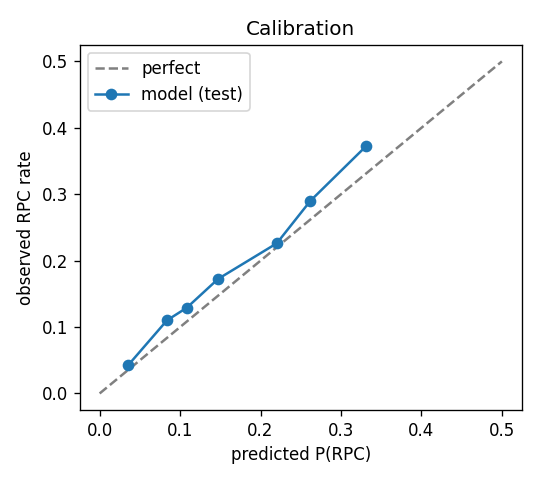

In [6]:
# Calibration: does a predicted probability match what actually happens?
observed, predicted = calibration_curve(y, test_pred, n_bins=10, strategy="quantile")
display(pd.DataFrame({"predicted P(RPC)": predicted.round(3), "observed RPC rate": observed.round(3)}))

plt.figure(figsize=(4.5, 4))
plt.plot([0, 0.5], [0, 0.5], "--", color="grey", label="perfect")
plt.plot(predicted, observed, "o-", label="model (test)")
plt.xlabel("predicted P(RPC)"); plt.ylabel("observed RPC rate"); plt.title("Calibration"); plt.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "calibration.png", dpi=120); plt.show()

## 6. Score every phone as of today and check the HMM against verified labels
To get the **current** state of every phone we add one "what if we called tomorrow at 11:00" row per phone (`real = 0`). The HMM ages the belief up to that moment without adding fake evidence, and all features are computed with exactly the same code as for real calls. The same trick is used later for the moment each historical skip-trace was triggered.

In [7]:
def make_query_rows(phone_rows, when, query_id):
    """One 'what if we called at `when`' row per phone (real = 0: no outcome, adds no evidence)."""
    q = phone_rows[PAIR].copy()
    q["attempt_ts"] = when
    q["query_id"] = query_id
    q["channel"] = "tele_agent"
    q["symbol"] = "NO_ANSWER"
    for col in ["is_rpc", "label_noisy", "dead_net", "rejected", "wrong_number", "real"]:
        q[col] = 0
    return q


# (a) production: every phone, tomorrow 11:00
asof_queries = make_query_rows(phones, ASOF + pd.Timedelta(days=1, hours=11), "asof")

# (b) one set of rows per historical skip-trace: the account's phones that already existed that day
traces = traces.reset_index(drop=True)
traces["query_id"] = "trace_" + traces.index.astype(str)
trace_phones = traces.merge(phones, on="account_id")
trace_phones = trace_phones[trace_phones.added_date < trace_phones.trace_date]        # phones found BY the trace are excluded
trace_queries = make_query_rows(trace_phones, trace_phones.trace_date + pd.Timedelta(hours=11), trace_phones.query_id)

all_rows = pd.concat([dials, asof_queries, trace_queries], ignore_index=True)
all_rows["real"] = all_rows.real.astype(int)
all_rows = build_features(add_hmm_beliefs(attach_metadata(all_rows)))

queries = all_rows[all_rows.real == 0].copy()
queries["p_rpc"] = predict(model, calibrator, queries, ALL_FEATURES)
current = queries[queries.query_id == "asof"].copy()                       # state of every phone right now
print(f"{len(current):,} phones scored as of {ASOF.date()}")

5,719 phones scored as of 2026-06-30


In [8]:
# Sanity check: does the HMM's belief agree with the independently VERIFIED contact points?
CLASS_OF = {"borrower_number": "VALID", "third_party_number": "THIRD", "not_borrower_number": "RECYC",
            "switched_off": "DEAD", "invalid_number": "DEAD"}
current["hmm_class"] = (current[["P_valid", "P_THIRD", "P_RECYC", "P_DEAD"]]
                        .set_axis(["VALID", "THIRD", "RECYC", "DEAD"], axis=1).idxmax(axis=1))
check = verified.merge(current[PAIR + ["hmm_class"]], on=PAIR)
check["verified_class"] = check.verified_status.map(CLASS_OF)

print(f"Verified phones: {len(check)} | HMM accuracy: {(check.hmm_class == check.verified_class).mean():.1%}")
display(pd.crosstab(check.verified_class, check.hmm_class, rownames=["verified"], colnames=["HMM says"]))

Verified phones: 250 | HMM accuracy: 82.4%
HMM says  DEAD  RECYC  THIRD  VALID
verified                           
DEAD        15      0      1      6
RECYC        4      8      3     12
THIRD        1      1     67      5
VALID        0      1     10    116


## 7. Skip-trace: will a trace find a new contact?
For each historical skip-trace we look at the account **on the day of the trace** (best phone's P(RPC), how likely the phones are still valid / avoiding, share of dead or rejected calls, balance) and predict whether the trace found something (`new_phone_found` or `new_address_found`).

* Model: standardise + `LogisticRegression` (simple and explainable).
* Fit on traces of **train** accounts; score on **validation + test** accounts.

In [9]:
def summarise_accounts(q, by):
    """Collapse the phone-level rows into one row per `by` (an account, or one historical trace)."""
    out = q.groupby(by).agg(
        p_best=("p_rpc", "max"),                       # best phone's chance of an RPC on one call
        valid_max=("P_valid", "max"),                  # is at least one phone still the borrower's?
        avoid_max=("P_AVOID", "max"),
        recycled_max=("P_RECYC", "max"),
        n_attempts=("prev_attempts", "sum"),
        n_dead=("prev_dead", "sum"),
        n_reject=("prev_reject", "sum"))
    out["dead_rate"] = out.n_dead / out.n_attempts.replace(0, np.nan)
    out["reject_rate"] = out.n_reject / out.n_attempts.replace(0, np.nan)
    return out.fillna({"dead_rate": 0, "reject_rate": 0})


trace_features = ["p_best", "valid_max", "avoid_max", "dead_rate", "reject_rate", "n_attempts", "log_overdue"]

trace_table = traces.merge(summarise_accounts(queries[queries.query_id.str.startswith("trace_", na=False)], by="query_id"),
                           left_on="query_id", right_index=True, how="left")
trace_table = trace_table.merge(accounts[["account_id", "overdue_start"]], on="account_id")
trace_table["log_overdue"] = np.log1p(trace_table.overdue_start)
trace_table["split"] = trace_table.account_id.map(splits.set_index("account_id").split)
trace_table["hit"] = (trace_table.result != "no_new_info").astype(int)
trace_table[trace_features] = trace_table[trace_features].fillna(0)

fit_rows  = trace_table[trace_table.split == "train"]
eval_rows = trace_table[trace_table.split != "train"].copy()
trace_model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000))
trace_model.fit(fit_rows[trace_features], fit_rows.hit)
eval_rows["p_hit"] = trace_model.predict_proba(eval_rows[trace_features])[:, 1]

print(f"Traces: {len(trace_table)} (train {len(fit_rows)}, held-out {len(eval_rows)}) | overall hit rate {trace_table.hit.mean():.1%}")
print(f"Held-out AUC for 'will the trace find something?': {roc_auc_score(eval_rows.hit, eval_rows.p_hit):.3f}")
display(pd.Series(trace_model[-1].coef_[0], index=trace_features, name="coefficient (standardised)").round(3).to_frame())

Traces: 766 (train 523, held-out 243) | overall hit rate 22.8%
Held-out AUC for 'will the trace find something?': 0.796
             coefficient (standardised)
p_best                           -0.114
valid_max                        -0.416
avoid_max                        -0.117
dead_rate                        -0.158
reject_rate                      -0.448
n_attempts                        0.001
log_overdue                       0.062


## 8. Value of information (VOI) – is the trace worth its cost?
For an account the trace helps only if it finds a contact that is **better** than what we already have:

`VOI = P(trace finds a contact) x (chance to reach with the new contact - chance to reach with current ones) x RHO x N_WINDOWS x overdue amount - trace cost`

* **Chance to reach** within `H_CALLS` calls = `1 - (1 - p)^H_CALLS`, using the per-call probability `p` from the model.
* **New-contact reach**: the observed RPC rate on phones that came from earlier skip-traces.
* **RHO = 0.049**: the extra share of the overdue amount paid within 14 days after a right-party contact (an assumption from an earlier within-account analysis of the payment data; change it here if you disagree).
* **Trace cost** = average `cost_inr` in `skip_traces.csv`.

An account whose phones still look valid (an **avoider**) gets a lower chance of a trace hit (see the coefficients in section 7), so its VOI is lower; an account whose numbers are **dead** with a large balance gets the highest VOI. Because VOI also scales with the overdue amount, a large-balance avoider can still qualify for a trace.

In [10]:
TRACE_COST = traces.cost_inr.mean()
P_NEW_PHONE = dials.merge(phones[PAIR + ["source"]], on=PAIR).query("source == 'skip_trace'").is_rpc.mean()
reach_with_new_contact = 1 - (1 - P_NEW_PHONE) ** H_CALLS
print(f"Average trace cost Rs {TRACE_COST:.0f} | RPC rate on traced phones {P_NEW_PHONE:.1%} -> reach in {H_CALLS} calls {reach_with_new_contact:.1%}")


def add_voi(df):
    reach_now = 1 - (1 - df.p_best) ** H_CALLS
    gain = (reach_with_new_contact - reach_now).clip(lower=0)
    df["voi"] = df.p_hit * gain * RHO * N_WINDOWS * df.overdue_start - TRACE_COST
    return df


eval_rows = add_voi(eval_rows)

# Compare policies on the held-out historical traces (hit rate and money spent are observed, not modelled)
def describe(name, rows):
    return {"policy": name, "traces": len(rows), "spend (Rs)": round(len(rows) * TRACE_COST),
            "hits": int(rows.hit.sum()), "hit rate": round(rows.hit.mean(), 3)}

display(pd.DataFrame([
    describe("Current rule: trace everything that was triggered", eval_rows),
    describe("Trace only if VOI > 0", eval_rows[eval_rows.voi > 0]),
]).set_index("policy"))

Average trace cost Rs 104 | RPC rate on traced phones 20.6% -> reach in 10 calls 90.1%
                                                   traces  spend (Rs)  hits  hit rate
policy                                                                               
Current rule: trace everything that was triggered     243       25268    61     0.251
Trace only if VOI > 0                                  54        5615    25     0.463


## 9. Final action for every account
Rules, applied in this order:
1. **TRACE** – VOI > 0.
2. **DIAL** – the best phone has P(RPC) above `SWITCH_THRESHOLD`.
3. **SWITCH_CHANNEL** – the phone is probably still the borrower's but we hardly ever reach them (*avoiding*): use WhatsApp / field instead of redialling.
4. **DROP_NUMBER** – dead numbers and not worth tracing.

A **do-not-call list** (compliance) is produced separately: numbers that are probably recycled to a stranger, or where a stranger has already said "wrong number".

In [11]:
accounts_now = summarise_accounts(current, by="account_id")

master = accounts[["account_id", "lender_id", "portfolio", "bucket_start", "overdue_start"]].merge(
    accounts_now, left_on="account_id", right_index=True, how="left").fillna(0)
master["log_overdue"] = np.log1p(master.overdue_start)
master["p_hit"] = trace_model.predict_proba(master[trace_features])[:, 1]
master = add_voi(master)


def choose_action(row):
    if row.voi > 0:
        return "TRACE"
    if row.p_best >= SWITCH_THRESHOLD:
        return "DIAL"
    if row.valid_max >= 0.5:
        return "SWITCH_CHANNEL"
    return "DROP_NUMBER"


master["action"] = master.apply(choose_action, axis=1)

do_not_call = current[(current.P_RECYC >= RECYCLED_THRESHOLD) | (current.prev_wrong >= 1)]
do_not_call = do_not_call[PAIR + ["relation_recorded", "P_RECYC", "prev_wrong"]]

master.round(4).to_csv(OUT_DIR / "account_actions.csv", index=False)
(master[master.voi > 0].sort_values("voi", ascending=False)
 [["account_id", "overdue_start", "p_best", "p_hit", "voi"]].round(3).to_csv(OUT_DIR / "skip_trace_queue.csv", index=False))
do_not_call.round(3).to_csv(OUT_DIR / "do_not_call_list.csv", index=False)
current[PAIR + [f"P_{s}" for s in STATES] + ["p_rpc"]].round(4).to_csv(OUT_DIR / "phone_scores.csv", index=False)

print("Accounts per action:"); display(master.action.value_counts().to_frame("accounts"))
print(f"Skip-trace queue: {(master.voi > 0).sum()} accounts | do-not-call numbers: {len(do_not_call)}")
display(master.sort_values("voi", ascending=False).head(10)[["account_id", "overdue_start", "p_best", "p_hit", "voi", "action"]].round(3))

Accounts per action:
                accounts
action                  
DIAL                2003
TRACE                259
SWITCH_CHANNEL        78
DROP_NUMBER           60
Skip-trace queue: 259 accounts | do-not-call numbers: 827
     account_id  overdue_start  p_best  p_hit       voi action
1149   AC001150       162600.0   0.000  0.412  5781.377  TRACE
2181   AC002182       217800.0   0.050  0.463  4814.814  TRACE
1109   AC001110       115200.0   0.000  0.445  4400.941  TRACE
1405   AC001406       199800.0   0.050  0.440  4186.460  TRACE
2215   AC002216       137500.0   0.036  0.467  3648.106  TRACE
154    AC000155       105900.0   0.000  0.397  3592.300  TRACE
1382   AC001383       113400.0   0.050  0.453  2405.767  TRACE
1138   AC001139       102450.0   0.050  0.477  2281.079  TRACE
1085   AC001086        73800.0   0.008  0.396  2267.049  TRACE
2061   AC002062        63750.0   0.000  0.399  2130.379  TRACE


## 10. Summary, assumptions and limitations
**What the notebook does:** (1) tracks each phone's hidden state with an ageing HMM, (2) predicts the chance that the next call reaches the borrower with a calibrated gradient-boosting model, (3) decides whether a skip-trace is worth its cost with a value-of-information rule, and (4) writes the per-account actions, the trace queue, the phone scores and a compliance do-not-call list to `outputs/`.

**Honest limitations**
* HMM parameters are **domain-informed and fixed**, not learned. A learned (EM-trained) HMM would be a natural next step.
* Per-call AUC cannot be very high: even a healthy number only answers about one call in four, so the ceiling is limited by chance.
* `RHO` and `N_WINDOWS` are assumptions; the VOI ranking depends on them. Hit rates and costs in the trace comparison are observed, rupee value is not.
* The trace model learned only from accounts that were traced under the old rule, so scores far outside that population are extrapolations.
* Only phones are modelled; addresses / field visits (Phase 2 of the problem) are not covered here.
* Wrong-number logs can be spurious, so the do-not-call rule can over-block a few valid numbers (a safer choice for compliance).